In [1]:
import sys, os, ast, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, root_mean_squared_error,
    r2_score, median_absolute_error, mean_absolute_percentage_error,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)

sys.path.append(os.path.abspath('..'))
from src.models import MLP
from src.train import treinar

def fixar_sementes(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def criar_otimizador(nome, params, lr, wd):
    if nome == "SGD":
        return torch.optim.SGD(params, lr=lr, weight_decay=wd)
    elif nome == "SGD_momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    elif nome == "RMSprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=wd)
    elif nome == "Adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=wd)
    elif nome == "AdamW":
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(nome)

BASELINE = {
    "hidden": [32, 32], "activation": "ReLU", "opt": "Adam",
    "lr": 1e-3, "batch_size": 32, "dropout": 0.0, "weight_decay": 0.0
}

def carregar_campeao(caminho_csv):
    row = pd.read_csv(caminho_csv).iloc[0]
    return {
        "hidden": ast.literal_eval(row["hidden"]) if isinstance(row["hidden"], str) else row["hidden"],
        "activation": row["activation"],
        "opt": row["opt"],
        "lr": float(row["lr"]),
        "batch_size": int(row["batch_size"]),
        "dropout": float(row["dropout"]),
        "weight_decay": float(row["weight_decay"]),
    }

CFG_REG = carregar_campeao('../reports/tables/busca_final_regressao.csv')
CFG_CLF = carregar_campeao('../reports/tables/busca_final_classificacao.csv')

print("Campeão Regressão:", CFG_REG)
print("Campeão Classificação:", CFG_CLF)

Campeão Regressão: {'hidden': [32, 32], 'activation': 'GELU', 'opt': 'AdamW', 'lr': 0.005, 'batch_size': 32, 'dropout': 0.2, 'weight_decay': 1e-05}
Campeão Classificação: {'hidden': [64, 64], 'activation': 'Tanh', 'opt': 'RMSprop', 'lr': 0.003, 'batch_size': 16, 'dropout': 0.3, 'weight_decay': 0.0}


In [2]:
target_reg = 'Mental_Wellbeing_Score'
df_tr = pd.read_csv('../data/processed/train_regression.csv')
df_te = pd.read_csv('../data/processed/test_regression.csv')
features_reg = df_tr.drop(columns=[target_reg]).columns.tolist()

Xr_full, yr_full = df_tr[features_reg].values, df_tr[target_reg].values
Xr_test, yr_test = df_te[features_reg].values, df_te[target_reg].values
Xr_tr, Xr_va, yr_tr, yr_va = train_test_split(Xr_full, yr_full, test_size=0.2, random_state=42)

sc_Xr = StandardScaler().fit(Xr_tr)
sc_yr = StandardScaler().fit(yr_tr.reshape(-1, 1))

Xr_tr_t = torch.tensor(sc_Xr.transform(Xr_tr), dtype=torch.float32)
yr_tr_t = torch.tensor(sc_yr.transform(yr_tr.reshape(-1, 1)), dtype=torch.float32)
Xr_va_t = torch.tensor(sc_Xr.transform(Xr_va), dtype=torch.float32)
yr_va_t = torch.tensor(sc_yr.transform(yr_va.reshape(-1, 1)), dtype=torch.float32)
Xr_te_t = torch.tensor(sc_Xr.transform(Xr_test), dtype=torch.float32)

def treinar_reg(cfg):
    fixar_sementes(42)
    dl_tr = DataLoader(TensorDataset(Xr_tr_t, yr_tr_t), batch_size=cfg["batch_size"], shuffle=True)
    dl_va = DataLoader(TensorDataset(Xr_va_t, yr_va_t), batch_size=64, shuffle=False)
    arq = {"in_dim": Xr_tr.shape[1], "out_dim": 1, "hidden": cfg["hidden"],
           "activation": cfg["activation"], "dropout": cfg["dropout"]}
    mod = MLP(**arq)
    otim = criar_otimizador(cfg["opt"], mod.parameters(), cfg["lr"], cfg["weight_decay"])
    hist = treinar(mod, dl_tr, dl_va, nn.MSELoss(), otim, n_epocas=200, paciencia=20)
    return mod, arq, hist

mod_reg_base, _, _ = treinar_reg(BASELINE)
mod_reg_final, arq_reg_final, hist_reg = treinar_reg(CFG_REG)

# Salva checkpoint completo da Regressão
ckpt_reg_path = '../models/modelo_regressao.pt'
torch.save({
    "task": "regression",
    "state_dict": mod_reg_final.state_dict(),
    "config": arq_reg_final,
    "features": features_reg,
    "x_media": torch.tensor(sc_Xr.mean_, dtype=torch.float32),
    "x_desvio": torch.tensor(sc_Xr.scale_, dtype=torch.float32),
    "y_media": float(sc_yr.mean_[0]),
    "y_desvio": float(sc_yr.scale_[0]),
}, ckpt_reg_path)

# Verificação de fidelidade (memória vs. arquivo recarregado)
ckpt = torch.load(ckpt_reg_path, map_location="cpu", weights_only=True)
mod_reg_load = MLP(**ckpt["config"])
mod_reg_load.load_state_dict(ckpt["state_dict"])
mod_reg_load.eval()
mod_reg_final.eval()

with torch.inference_mode():
    out_mem = mod_reg_final(Xr_te_t)
    out_load = mod_reg_load(Xr_te_t)

diff_reg = (out_mem - out_load).abs().max().item()
print(f"[Fidelidade Regressão] torch.allclose: {torch.allclose(out_mem, out_load)} | Diff máx abs: {diff_reg:.2e}")

[Fidelidade Regressão] torch.allclose: True | Diff máx abs: 0.00e+00


,Modelo,Conjunto,MAE,MSE,RMSE,MAPE,R2,MedAE
0,Baseline,Treino,0.380826,0.234573,0.484328,1.313945,0.758169,0.317061
1,Baseline,Teste,0.448906,0.321781,0.567258,1.364322,0.700198,0.366014
2,Final (Recarregado),Treino,0.259231,0.108840,0.329909,0.983576,0.887793,0.207136
3,Final (Recarregado),Teste,0.400625,0.264368,0.514167,1.298157,0.753690,0.322266


Gap de Generalização Regressão (RMSE_teste - RMSE_treino): 0.1843


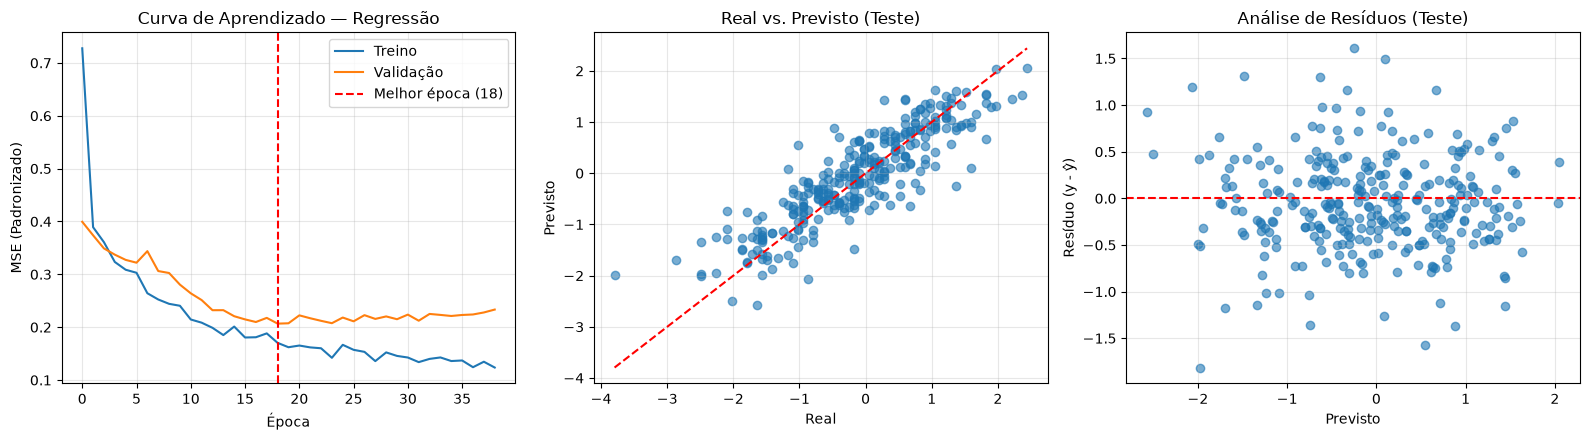

In [3]:
def metricas_reg(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MedAE": median_absolute_error(y_true, y_pred),
    }

def prever_reg_orig(mod, X_t):
    mod.eval()
    with torch.inference_mode():
        p = mod(X_t).numpy()
    return sc_yr.inverse_transform(p).ravel()

rows_reg = []
for nome, mod in [("Baseline", mod_reg_base), ("Final (Recarregado)", mod_reg_load)]:
    for conj, X_t, y_true in [("Treino", Xr_tr_t, yr_tr), ("Teste", Xr_te_t, yr_test)]:
        y_pred = prever_reg_orig(mod, X_t)
        rows_reg.append({"Modelo": nome, "Conjunto": conj, **metricas_reg(y_true, y_pred)})

df_eval_reg = pd.DataFrame(rows_reg)
df_eval_reg.to_csv('../reports/tables/avaliacao_regressao.csv', index=False)
display(df_eval_reg)

# Gap de generalização (Final)
rmse_tr = df_eval_reg.query("Modelo == 'Final (Recarregado)' and Conjunto == 'Treino'")["RMSE"].values[0]
rmse_te = df_eval_reg.query("Modelo == 'Final (Recarregado)' and Conjunto == 'Teste'")["RMSE"].values[0]
print(f"Gap de Generalização Regressão (RMSE_teste - RMSE_treino): {rmse_te - rmse_tr:.4f}")

# Gráficos: Curva com ponto de parada + Real vs Previsto + Resíduos
y_pred_te_reg = prever_reg_orig(mod_reg_load, Xr_te_t)
residuos = yr_test - y_pred_te_reg
melhor_ep = int(np.argmin(hist_reg["val"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(hist_reg["treino"], label="Treino")
axes[0].plot(hist_reg["val"], label="Validação")
axes[0].axvline(melhor_ep, color="red", linestyle="--", label=f"Melhor época ({melhor_ep})")
axes[0].set_title("Curva de Aprendizado — Regressão")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("MSE (Padronizado)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].scatter(yr_test, y_pred_te_reg, alpha=0.6)
lims = [min(yr_test.min(), y_pred_te_reg.min()), max(yr_test.max(), y_pred_te_reg.max())]
axes[1].plot(lims, lims, 'r--')
axes[1].set_title("Real vs. Previsto (Teste)")
axes[1].set_xlabel("Real"); axes[1].set_ylabel("Previsto"); axes[1].grid(alpha=0.3)

axes[2].scatter(y_pred_te_reg, residuos, alpha=0.6)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_title("Análise de Resíduos (Teste)")
axes[2].set_xlabel("Previsto"); axes[2].set_ylabel("Resíduo (y - ŷ)"); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/avaliacao_regressao.png', dpi=150)
plt.show()

In [4]:
target_clf = 'Addiction_Level'
df_tr = pd.read_csv('../data/processed/train_classification.csv')
df_te = pd.read_csv('../data/processed/test_classification.csv')
features_clf = df_tr.drop(columns=[target_clf]).columns.tolist()

Xc_full, yc_full = df_tr[features_clf].values, df_tr[target_clf].values
Xc_test, yc_test = df_te[features_clf].values, df_te[target_clf].values
Xc_tr, Xc_va, yc_tr, yc_va = train_test_split(Xc_full, yc_full, test_size=0.2, random_state=42, stratify=yc_full)

sc_Xc = StandardScaler().fit(Xc_tr)
Xc_tr_t = torch.tensor(sc_Xc.transform(Xc_tr), dtype=torch.float32)
yc_tr_t = torch.tensor(yc_tr, dtype=torch.long)
Xc_va_t = torch.tensor(sc_Xc.transform(Xc_va), dtype=torch.float32)
yc_va_t = torch.tensor(yc_va, dtype=torch.long)
Xc_te_t = torch.tensor(sc_Xc.transform(Xc_test), dtype=torch.float32)

def treinar_clf(cfg):
    fixar_sementes(42)
    dl_tr = DataLoader(TensorDataset(Xc_tr_t, yc_tr_t), batch_size=cfg["batch_size"], shuffle=True)
    dl_va = DataLoader(TensorDataset(Xc_va_t, yc_va_t), batch_size=64, shuffle=False)
    arq = {"in_dim": Xc_tr.shape[1], "out_dim": 4, "hidden": cfg["hidden"],
           "activation": cfg["activation"], "dropout": cfg["dropout"]}
    mod = MLP(**arq)
    otim = criar_otimizador(cfg["opt"], mod.parameters(), cfg["lr"], cfg["weight_decay"])
    hist = treinar(mod, dl_tr, dl_va, nn.CrossEntropyLoss(), otim, n_epocas=200, paciencia=20)
    return mod, arq, hist

mod_clf_base, _, _ = treinar_clf(BASELINE)
mod_clf_final, arq_clf_final, hist_clf = treinar_clf(CFG_CLF)

# Salva checkpoint completo da Classificação
ckpt_clf_path = '../models/modelo_classificacao.pt'
torch.save({
    "task": "classification",
    "state_dict": mod_clf_final.state_dict(),
    "config": arq_clf_final,
    "features": features_clf,
    "classes": ["Classe_0", "Classe_1", "Classe_2", "Classe_3"],
    "x_media": torch.tensor(sc_Xc.mean_, dtype=torch.float32),
    "x_desvio": torch.tensor(sc_Xc.scale_, dtype=torch.float32),
}, ckpt_clf_path)

# Verificação de fidelidade
ckpt = torch.load(ckpt_clf_path, map_location="cpu", weights_only=True)
mod_clf_load = MLP(**ckpt["config"])
mod_clf_load.load_state_dict(ckpt["state_dict"])
mod_clf_load.eval()
mod_clf_final.eval()

with torch.inference_mode():
    out_mem = mod_clf_final(Xc_te_t)
    out_load = mod_clf_load(Xc_te_t)

diff_clf = (out_mem - out_load).abs().max().item()
print(f"[Fidelidade Classificação] torch.allclose: {torch.allclose(out_mem, out_load)} | Diff máx abs: {diff_clf:.2e}")

[Fidelidade Classificação] torch.allclose: True | Diff máx abs: 0.00e+00


,Modelo,Conjunto,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,ROC_AUC_macro,PR_AUC_macro
0,Baseline,Treino,0.856250,0.857058,0.857460,0.857029,0.855663,0.974153,0.926247
1,Baseline,Teste,0.726667,0.726885,0.727612,0.726084,0.723683,0.926832,0.779945
2,Final (Recarregado),Treino,0.806250,0.814635,0.810146,0.811220,0.807740,0.955394,0.874493
3,Final (Recarregado),Teste,0.776667,0.776553,0.777282,0.776072,0.777500,0.932753,0.812644


Gap de Generalização Classificação (F1_treino - F1_teste): 0.0351


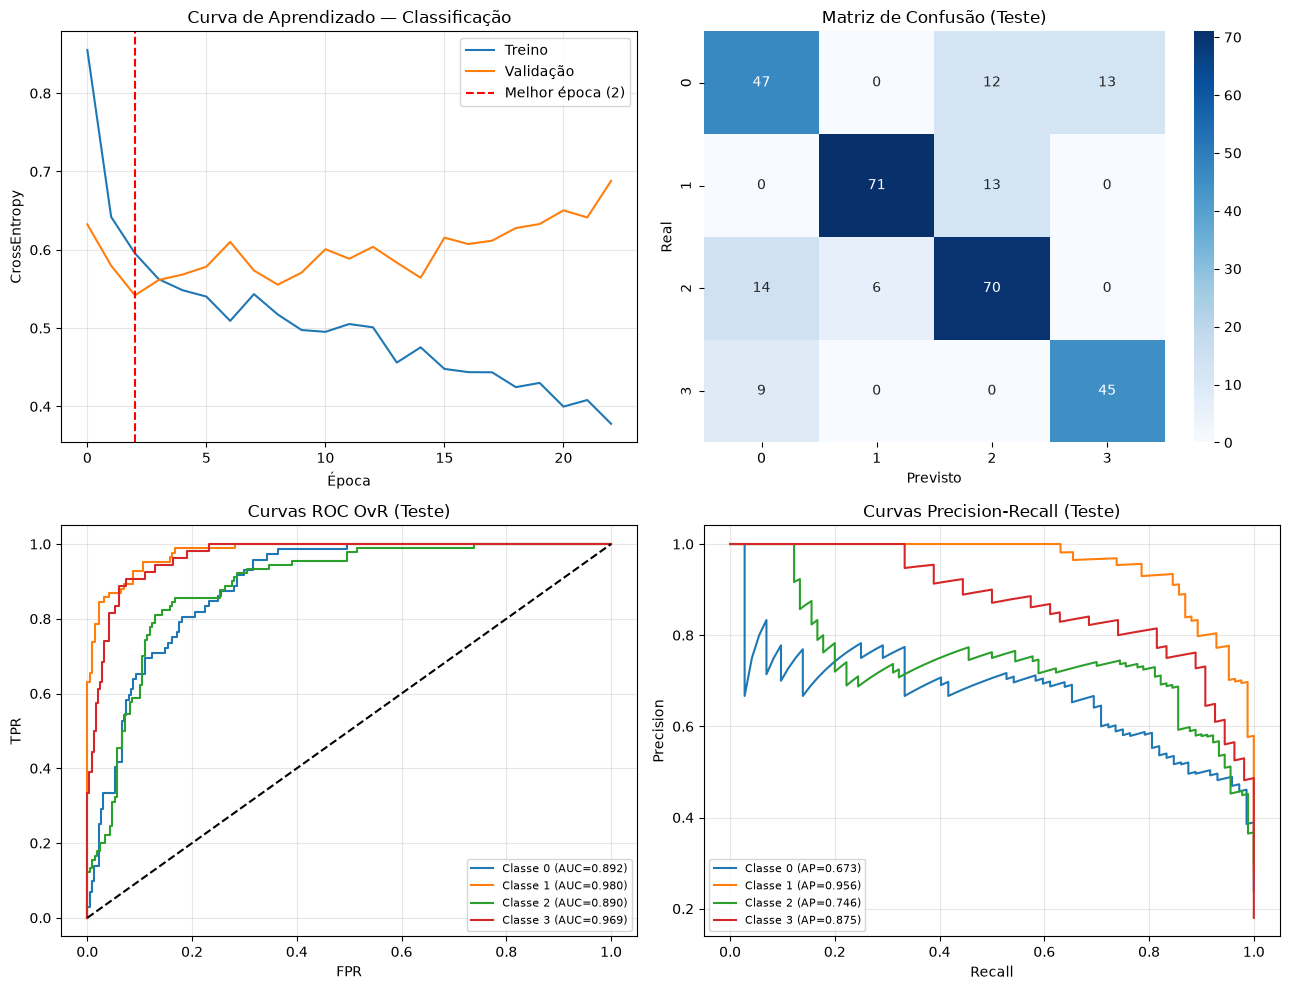

In [5]:
def prever_clf(mod, X_t):
    mod.eval()
    with torch.inference_mode():
        logits = mod(X_t)
        probs = torch.softmax(logits, dim=1).numpy()
        preds = probs.argmax(axis=1)
    return preds, probs

def metricas_clf(y_true, y_pred, probs):
    y_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC_AUC_macro": roc_auc_score(y_bin, probs, average="macro", multi_class="ovr"),
        "PR_AUC_macro": average_precision_score(y_bin, probs, average="macro"),
    }

rows_clf = []
for nome, mod in [("Baseline", mod_clf_base), ("Final (Recarregado)", mod_clf_load)]:
    for conj, X_t, y_true in [("Treino", Xc_tr_t, yc_tr), ("Teste", Xc_te_t, yc_test)]:
        preds, probs = prever_clf(mod, X_t)
        rows_clf.append({"Modelo": nome, "Conjunto": conj, **metricas_clf(y_true, preds, probs)})

df_eval_clf = pd.DataFrame(rows_clf)
df_eval_clf.to_csv('../reports/tables/avaliacao_classificacao.csv', index=False)
display(df_eval_clf)

f1_tr = df_eval_clf.query("Modelo == 'Final (Recarregado)' and Conjunto == 'Treino'")["F1_macro"].values[0]
f1_te = df_eval_clf.query("Modelo == 'Final (Recarregado)' and Conjunto == 'Teste'")["F1_macro"].values[0]
print(f"Gap de Generalização Classificação (F1_treino - F1_teste): {f1_tr - f1_te:.4f}")

# Gráficos: Curva de Aprendizado + Matriz de Confusão + ROC + PR
preds_te, probs_te = prever_clf(mod_clf_load, Xc_te_t)
y_bin_te = label_binarize(yc_test, classes=[0, 1, 2, 3])
melhor_ep_c = int(np.argmin(hist_clf["val"]))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].plot(hist_clf["treino"], label="Treino")
axes[0, 0].plot(hist_clf["val"], label="Validação")
axes[0, 0].axvline(melhor_ep_c, color="red", linestyle="--", label=f"Melhor época ({melhor_ep_c})")
axes[0, 0].set_title("Curva de Aprendizado — Classificação")
axes[0, 0].set_xlabel("Época"); axes[0, 0].set_ylabel("CrossEntropy"); axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

cm = confusion_matrix(yc_test, preds_te)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 1])
axes[0, 1].set_title("Matriz de Confusão (Teste)")
axes[0, 1].set_xlabel("Previsto"); axes[0, 1].set_ylabel("Real")

for c in range(4):
    fpr, tpr, _ = roc_curve(y_bin_te[:, c], probs_te[:, c])
    axes[1, 0].plot(fpr, tpr, label=f"Classe {c} (AUC={roc_auc_score(y_bin_te[:, c], probs_te[:, c]):.3f})")
axes[1, 0].plot([0, 1], [0, 1], 'k--')
axes[1, 0].set_title("Curvas ROC OvR (Teste)"); axes[1, 0].set_xlabel("FPR"); axes[1, 0].set_ylabel("TPR")
axes[1, 0].legend(fontsize=8); axes[1, 0].grid(alpha=0.3)

for c in range(4):
    prec, rec, _ = precision_recall_curve(y_bin_te[:, c], probs_te[:, c])
    axes[1, 1].plot(rec, prec, label=f"Classe {c} (AP={average_precision_score(y_bin_te[:, c], probs_te[:, c]):.3f})")
axes[1, 1].set_title("Curvas Precision-Recall (Teste)"); axes[1, 1].set_xlabel("Recall"); axes[1, 1].set_ylabel("Precision")
axes[1, 1].legend(fontsize=8); axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/avaliacao_classificacao.png', dpi=150)
plt.show()

In [6]:
# 5-Fold Regressão
kf_reg = KFold(n_splits=5, shuffle=True, random_state=42)
rmses_cv = []
for fold, (tr_idx, va_idx) in enumerate(kf_reg.split(Xr_full)):
    sc_x = StandardScaler().fit(Xr_full[tr_idx])
    sc_y = StandardScaler().fit(yr_full[tr_idx].reshape(-1, 1))
    dl_tr = DataLoader(TensorDataset(
        torch.tensor(sc_x.transform(Xr_full[tr_idx]), dtype=torch.float32),
        torch.tensor(sc_y.transform(yr_full[tr_idx].reshape(-1, 1)), dtype=torch.float32)
    ), batch_size=CFG_REG["batch_size"], shuffle=True)
    dl_va = DataLoader(TensorDataset(
        torch.tensor(sc_x.transform(Xr_full[va_idx]), dtype=torch.float32),
        torch.tensor(sc_y.transform(yr_full[va_idx].reshape(-1, 1)), dtype=torch.float32)
    ), batch_size=64, shuffle=False)
    fixar_sementes(42 + fold)
    mod = MLP(Xr_full.shape[1], 1, CFG_REG["hidden"], CFG_REG["activation"], CFG_REG["dropout"])
    otim = criar_otimizador(CFG_REG["opt"], mod.parameters(), CFG_REG["lr"], CFG_REG["weight_decay"])
    treinar(mod, dl_tr, dl_va, nn.MSELoss(), otim, n_epocas=200, paciencia=20)
    mod.eval()
    with torch.inference_mode():
        p = sc_y.inverse_transform(mod(torch.tensor(sc_x.transform(Xr_full[va_idx]), dtype=torch.float32)).numpy()).ravel()
    rmses_cv.append(root_mean_squared_error(yr_full[va_idx], p))

# 5-Fold Classificação
skf_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1s_cv = []
for fold, (tr_idx, va_idx) in enumerate(skf_clf.split(Xc_full, yc_full)):
    sc_x = StandardScaler().fit(Xc_full[tr_idx])
    dl_tr = DataLoader(TensorDataset(
        torch.tensor(sc_x.transform(Xc_full[tr_idx]), dtype=torch.float32),
        torch.tensor(yc_full[tr_idx], dtype=torch.long)
    ), batch_size=CFG_CLF["batch_size"], shuffle=True)
    dl_va = DataLoader(TensorDataset(
        torch.tensor(sc_x.transform(Xc_full[va_idx]), dtype=torch.float32),
        torch.tensor(yc_full[va_idx], dtype=torch.long)
    ), batch_size=64, shuffle=False)
    fixar_sementes(42 + fold)
    mod = MLP(Xc_full.shape[1], 4, CFG_CLF["hidden"], CFG_CLF["activation"], CFG_CLF["dropout"])
    otim = criar_otimizador(CFG_CLF["opt"], mod.parameters(), CFG_CLF["lr"], CFG_CLF["weight_decay"])
    treinar(mod, dl_tr, dl_va, nn.CrossEntropyLoss(), otim, n_epocas=200, paciencia=20)
    mod.eval()
    with torch.inference_mode():
        p = mod(torch.tensor(sc_x.transform(Xc_full[va_idx]), dtype=torch.float32)).argmax(dim=1).numpy()
    f1s_cv.append(f1_score(yc_full[va_idx], p, average="macro"))

df_cv = pd.DataFrame([
    {"Tarefa": "Regressão", "Metrica": "RMSE", "Media_5Fold": np.mean(rmses_cv), "Std_5Fold": np.std(rmses_cv)},
    {"Tarefa": "Classificação", "Metrica": "F1_macro", "Media_5Fold": np.mean(f1s_cv), "Std_5Fold": np.std(f1s_cv)},
])
df_cv.to_csv('../reports/tables/kfold_5_final.csv', index=False)
display(df_cv)

,Tarefa,Metrica,Media_5Fold,Std_5Fold
0,Regressão,RMSE,0.467334,0.012375
1,Classificação,F1_macro,0.757944,0.025759
